# Framing Simulator: Does the Target Fit on the Sensor?

This notebook:
1. Catalogs the most common **telescopes, cameras, and smart telescopes**;
2. Computes the **field of view (FOV)** and **pixel sampling** for any telescope + camera + accessory combination;
3. Determines whether a deep-sky target **fits cleanly in the frame**, or is **too large / too small** for that focal length.

Each cell defines one building block. The **final cell** brings everything together in `analyze(...)`.

## 1. Imports

In [1]:
import math
import unicodedata

import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse, Rectangle

## 2. Telescope & Lens Catalog

Aperture diameter and focal length in mm (manufacturer specifications).

In [2]:
TELESCOPES = {
    'Sky-Watcher 130PDS':          {'type': 'Newtonian',           'aperture_mm': 130,  'focal_mm': 650},
    'Sky-Watcher 150PDS':          {'type': 'Newtonian',           'aperture_mm': 150,  'focal_mm': 750},
    'Sky-Watcher 200PDS':          {'type': 'Newtonian',           'aperture_mm': 200,  'focal_mm': 1000},
    'Sky-Watcher Evostar 72ED':    {'type': 'Refractor',           'aperture_mm': 72,   'focal_mm': 420},
    'Sky-Watcher Evostar 80ED':    {'type': 'Refractor',           'aperture_mm': 80,   'focal_mm': 600},
    'William Optics RedCat 51':    {'type': 'Refractor',           'aperture_mm': 51,   'focal_mm': 250},
    'Askar FRA400':                {'type': 'Refractor',           'aperture_mm': 72,   'focal_mm': 400},
    'Sky-Watcher Skymax 127':      {'type': 'Maksutov',            'aperture_mm': 127,  'focal_mm': 1500},
    'Celestron NexStar 8SE':       {'type': 'Schmidt-Cassegrain',  'aperture_mm': 203,  'focal_mm': 2032},
    'Celestron RASA 8':            {'type': 'Rowe-Ackermann',      'aperture_mm': 203,  'focal_mm': 400},
    'Samyang 135mm f/2':           {'type': 'Camera lens',         'aperture_mm': 67.5, 'focal_mm': 135},
    'Canon EF 200mm f/2.8L':       {'type': 'Camera lens',         'aperture_mm': 71,   'focal_mm': 200},
}

print(len(TELESCOPES), 'telescopes:', ', '.join(TELESCOPES))

12 telescopes: Sky-Watcher 130PDS, Sky-Watcher 150PDS, Sky-Watcher 200PDS, Sky-Watcher Evostar 72ED, Sky-Watcher Evostar 80ED, William Optics RedCat 51, Askar FRA400, Sky-Watcher Skymax 127, Celestron NexStar 8SE, Celestron RASA 8, Samyang 135mm f/2, Canon EF 200mm f/2.8L


## 3. Camera Catalog

Sensor dimensions in mm, pixel pitch in microns (µm), and resolution in pixels.

In [3]:
CAMERAS = {
    'ZWO ASI120MC':      {'type': 'Planetary camera',      'width_mm': 4.8,  'height_mm': 3.6,  'pixel_um': 3.75, 'resolution': (1280, 960)},
    'ZWO ASI224MC':      {'type': 'Planetary camera',      'width_mm': 4.9,  'height_mm': 3.7,  'pixel_um': 3.75, 'resolution': (1304, 976)},
    'ZWO ASI462MC':      {'type': 'Planetary camera',      'width_mm': 5.6,  'height_mm': 3.2,  'pixel_um': 2.9,  'resolution': (1936, 1096)},
    'ZWO ASI533MC Pro':  {'type': 'Cooled astro camera',   'width_mm': 11.3, 'height_mm': 11.3, 'pixel_um': 3.76, 'resolution': (3008, 3008)},
    'ZWO ASI294MC Pro':  {'type': 'Cooled astro camera',   'width_mm': 19.1, 'height_mm': 13.0, 'pixel_um': 4.63, 'resolution': (4144, 2822)},
    'ZWO ASI2600MC Pro': {'type': 'Cooled astro camera',   'width_mm': 23.5, 'height_mm': 15.7, 'pixel_um': 3.76, 'resolution': (6248, 4176)},
    'ZWO ASI6200MC Pro': {'type': 'Cooled astro camera',   'width_mm': 36.0, 'height_mm': 24.0, 'pixel_um': 3.76, 'resolution': (9576, 6388)},
    'Canon EOS 2000D':   {'type': 'APS-C DSLR',            'width_mm': 22.3, 'height_mm': 14.9, 'pixel_um': 3.72, 'resolution': (6000, 4000)},
    'Nikon D5300':       {'type': 'APS-C DSLR',            'width_mm': 23.5, 'height_mm': 15.6, 'pixel_um': 3.92, 'resolution': (6000, 4000)},
    'Canon EOS 6D':      {'type': 'Full-frame DSLR',       'width_mm': 35.8, 'height_mm': 23.9, 'pixel_um': 6.55, 'resolution': (5472, 3648)},
    'Sony A7 III':       {'type': 'Full-frame mirrorless', 'width_mm': 35.6, 'height_mm': 23.8, 'pixel_um': 5.9,  'resolution': (6000, 4000)},
}

print(len(CAMERAS), 'cameras:', ', '.join(CAMERAS))

11 cameras: ZWO ASI120MC, ZWO ASI224MC, ZWO ASI462MC, ZWO ASI533MC Pro, ZWO ASI294MC Pro, ZWO ASI2600MC Pro, ZWO ASI6200MC Pro, Canon EOS 2000D, Nikon D5300, Canon EOS 6D, Sony A7 III


## 4. Smart Telescopes

Optics and sensor are integrated into a single unit: no separate camera or optical accessory is added.

In [4]:
SMART_TELESCOPES = {
    'ZWO Seestar S50': {'type': 'Smart telescope', 'aperture_mm': 50, 'focal_mm': 250,
                        'width_mm': 5.57, 'height_mm': 3.13, 'pixel_um': 2.9, 'resolution': (1920, 1080)},
    'Vaonis Vespera':  {'type': 'Smart telescope', 'aperture_mm': 50, 'focal_mm': 200,
                        'width_mm': 5.57, 'height_mm': 3.13, 'pixel_um': 2.9, 'resolution': (1920, 1080)},
}

print(len(SMART_TELESCOPES), 'smart telescopes:', ', '.join(SMART_TELESCOPES))

2 smart telescopes: ZWO Seestar S50, Vaonis Vespera


## 5. Optical Accessories

A focal reducer shortens the focal length (wider field), while a Barlow lens extends it (tighter field).

In [5]:
ACCESSORIES = {
    'none':          {'factor': 1.0},
    '0.8x Reducer':  {'factor': 0.8},
    '0.63x Reducer': {'factor': 0.63},
    '2x Barlow':     {'factor': 2.0},
}

print(len(ACCESSORIES), 'accessories:', ', '.join(ACCESSORIES))

4 accessories: none, 0.8x Reducer, 0.63x Reducer, 2x Barlow


## 6. Celestial Targets

Apparent angular size (major axis × minor axis) in arcminutes. Reference: the Full Moon spans about 31′.

In [6]:
TARGETS = {
    'M1':      {'name': 'Crab Nebula',            'size_max_arcmin': 6.0,   'size_min_arcmin': 4.0},
    'M13':     {'name': 'Hercules Cluster',       'size_max_arcmin': 20.0,  'size_min_arcmin': 20.0},
    'M27':     {'name': 'Dumbbell Nebula',        'size_max_arcmin': 8.0,   'size_min_arcmin': 5.7},
    'M31':     {'name': 'Andromeda Galaxy',       'size_max_arcmin': 178.0, 'size_min_arcmin': 70.0},
    'M33':     {'name': 'Triangulum Galaxy',      'size_max_arcmin': 71.0,  'size_min_arcmin': 42.0},
    'M42':     {'name': 'Great Orion Nebula',     'size_max_arcmin': 85.0,  'size_min_arcmin': 60.0},
    'M45':     {'name': 'Pleiades',               'size_max_arcmin': 110.0, 'size_min_arcmin': 110.0},
    'M51':     {'name': 'Whirlpool Galaxy',       'size_max_arcmin': 11.0,  'size_min_arcmin': 7.0},
    'M57':     {'name': 'Ring Nebula',            'size_max_arcmin': 1.4,   'size_min_arcmin': 1.0},
    'M81':     {'name': 'Bode Galaxy',            'size_max_arcmin': 27.0,  'size_min_arcmin': 14.0},
    'M101':    {'name': 'Pinwheel Galaxy',        'size_max_arcmin': 29.0,  'size_min_arcmin': 27.0},
    'M104':    {'name': 'Sombrero Galaxy',        'size_max_arcmin': 8.7,   'size_min_arcmin': 3.5},
    'NGC7000': {'name': 'North America Nebula',   'size_max_arcmin': 120.0, 'size_min_arcmin': 100.0},
    'C14':     {'name': 'Double Cluster',         'size_max_arcmin': 60.0,  'size_min_arcmin': 30.0},
    'Moon':    {'name': 'Full Moon',              'size_max_arcmin': 31.0,  'size_min_arcmin': 31.0},
}

print(len(TARGETS), 'targets:', ', '.join(TARGETS))

15 targets: M1, M13, M27, M31, M33, M42, M45, M51, M57, M81, M101, M104, NGC7000, C14, Moon


## 7. Fuzzy Name Lookup

Finds a catalog entry ignoring case, spaces, hyphens, and accents.
Partial names of at least 4 characters match when they uniquely identify one entry (`'redcat'`, `'andromeda'`, `'barlow'`).

In [7]:
def _normalize(text):
    text = unicodedata.normalize('NFKD', text)
    text = ''.join(c for c in text if not unicodedata.combining(c))
    return text.lower().replace(' ', '').replace('-', '').replace('_', '')


def find_entry(name, catalog):
    key = _normalize(name)
    for k, v in catalog.items():
        if key == _normalize(k):
            return k, v
    candidates = []
    if len(key) >= 4:
        candidates = [k for k, v in catalog.items()
                      if key in _normalize(k) or key in _normalize(v.get('name', ''))]
    if len(candidates) == 1:
        return candidates[0], catalog[candidates[0]]
    raise ValueError(f'{name!r} not found or ambiguous. Available choices: {list(catalog)}')


find_entry('redcat', TELESCOPES)

('William Optics RedCat 51',
 {'aperture_mm': 51, 'focal_mm': 250, 'type': 'Refractor'})

## 8. Rig Configuration

Combines telescope + camera + accessory and computes the **effective focal length** (`focal_mm × factor`).

In [8]:
def build_rig(telescope, camera=None, accessory='none'):
    try:
        tel_name, tel = find_entry(telescope, SMART_TELESCOPES)
        cam_name, sensor = 'built-in sensor', tel
        acc_name, factor = 'none', 1.0  # no external accessory on a smart telescope
    except ValueError:
        tel_name, tel = find_entry(telescope, TELESCOPES)
        if camera is None:
            raise ValueError(f'Please specify a camera for {tel_name}.')
        cam_name, sensor = find_entry(camera, CAMERAS)
        acc_name, acc = find_entry(accessory, ACCESSORIES)
        factor = acc['factor']

    name = f'{tel_name} + {cam_name}'
    if factor != 1.0:
        name += f' + {acc_name}'
    return {
        'name': name,
        'focal_mm': tel['focal_mm'] * factor,
        'aperture_mm': tel['aperture_mm'],
        'width_mm': sensor['width_mm'],
        'height_mm': sensor['height_mm'],
        'pixel_um': sensor['pixel_um'],
    }


build_rig('Evostar 72ED', 'Canon EOS 2000D', '0.8x Reducer')

{'aperture_mm': 72,
 'focal_mm': 336.0,
 'height_mm': 14.9,
 'name': 'Sky-Watcher Evostar 72ED + Canon EOS 2000D + 0.8x Reducer',
 'pixel_um': 3.72,
 'width_mm': 22.3}

## 9. Field of View (FOV)

Sky angle covered by a sensor side: `angle = 2 × arctan(sensor_mm / (2 × focal_mm))`, converted to arcminutes.
Width is always taken as the longer side of the sensor.

In [9]:
def angle_arcmin(size_mm, focal_mm):
    return math.degrees(2 * math.atan(size_mm / (2 * focal_mm))) * 60


def field_of_view(rig):
    f = rig['focal_mm']
    long_side = max(rig['width_mm'], rig['height_mm'])
    short_side = min(rig['width_mm'], rig['height_mm'])
    return {
        'width_arcmin': angle_arcmin(long_side, f),
        'height_arcmin': angle_arcmin(short_side, f),
        'diagonal_arcmin': angle_arcmin(math.hypot(long_side, short_side), f),
    }


field_of_view(build_rig('Evostar 72ED', 'Canon EOS 2000D'))

{'diagonal_arcmin': 219.44824505123137,
 'height_arcmin': 121.94537069079993,
 'width_arcmin': 182.48512097749747}

## 10. Pixel Sampling (Image Scale)

Sky angle subtended by a single pixel, in arcseconds: `206.265 × pixel_size (µm) / focal_length (mm)`.
Used to compute how many pixels the target spans across the sensor.

In [10]:
def pixel_sampling(rig):
    return 206.265 * rig['pixel_um'] / rig['focal_mm']


pixel_sampling(build_rig('Evostar 72ED', 'Canon EOS 2000D'))

1.8269185714285714

## 11. Framing Verdict

Assuming the camera is rotated to align the target's major axis with the sensor's long side, we measure the fraction of the frame occupied by the target:

| Frame Fill Ratio | Verdict |
|---|---|
| over 100% | **TOO LARGE**: target overflows the frame |
| 80% to 100% | **TIGHT FIT**: very little background margin |
| 30% to 80% | **IDEAL** |
| under 30%, but at least 150 px | **SMALL**: croppable |
| under 30% and under 150 px | **TOO SMALL**: insufficient resolution |

In [11]:
def evaluate_framing(target, fov, sampling_arcsec):
    major = target['size_max_arcmin']
    minor = target['size_min_arcmin']
    fill_ratio = max(major / fov['width_arcmin'], minor / fov['height_arcmin'])
    size_px = major * 60 / sampling_arcsec

    if fill_ratio > 1:
        verdict = 'TOO LARGE'
    elif fill_ratio >= 0.8:
        verdict = 'TIGHT FIT'
    elif fill_ratio >= 0.3:
        verdict = 'IDEAL'
    elif size_px >= 150:
        verdict = 'SMALL'
    else:
        verdict = 'TOO SMALL'
    return {'verdict': verdict, 'fill_ratio': fill_ratio, 'size_px': size_px}


test_rig = build_rig('Evostar 72ED', 'Canon EOS 2000D')
evaluate_framing(TARGETS['M42'], field_of_view(test_rig), pixel_sampling(test_rig))

{'fill_ratio': 0.4920235976167864,
 'size_px': 2791.5858318808487,
 'verdict': 'IDEAL'}

## 12. Mosaic Panel Calculator

When a target is too large for a single frame: computes the grid of panels (`width × height`) needed to cover it with a 15% overlap between adjacent panels.

In [12]:
def mosaic_panels(target, fov, overlap=0.15):
    usable_w = fov['width_arcmin'] * (1 - overlap)
    usable_h = fov['height_arcmin'] * (1 - overlap)
    nx = max(1, math.ceil(target['size_max_arcmin'] / usable_w))
    ny = max(1, math.ceil(target['size_min_arcmin'] / usable_h))
    return nx, ny


test_rig = build_rig('ZWO Seestar S50')
mosaic_panels(TARGETS['M31'], field_of_view(test_rig))

(3, 2)

## 13. Practical Framing Advice

Translates the verdict into actionable recommendations: mosaic grid, focal reducer, Barlow lens, or target focal length.

In [13]:
def framing_advice(evaluation, rig, target, fov):
    f = rig['focal_mm']
    r = evaluation['fill_ratio']
    px = evaluation['size_px']
    verdict = evaluation['verdict']

    if verdict == 'TOO LARGE':
        nx, ny = mosaic_panels(target, fov)
        return (f'Target overflows the frame: shoot a {nx} x {ny} panel mosaic, '
                f'or use a focal length of at most {f / r * 0.9:.0f} mm to fit it in a single frame.')
    if verdict == 'TIGHT FIT':
        return (f'Target fits with minimal margin. A 0.8x reducer '
                f'({f * 0.8:.0f} mm) would leave more surrounding sky background.')
    if verdict == 'IDEAL':
        return 'Balanced framing: the target fills the sensor nicely with surrounding sky margin.'
    if verdict == 'SMALL':
        return (f'Target is small in the field but well resolved ({px:.0f} px) for cropping. '
                f'To enlarge it: add a 2x Barlow ({f * 2:.0f} mm).')
    return (f'Target only spans {px:.0f} px: too small for this setup. '
            f'Aim for a focal length of at least {f * 150 / px:.0f} mm.')

## 14. Framing Diagram

Blue rectangle = sensor field of view; orange ellipse = celestial target, plotted on the same angular scale (arcminutes).

In [14]:
def plot_framing(target_label, target, fov, title=''):
    w, h = fov['width_arcmin'], fov['height_arcmin']
    major, minor = target['size_max_arcmin'], target['size_min_arcmin']

    fig, ax = plt.subplots(figsize=(6, 5))
    ax.add_patch(Rectangle((-w / 2, -h / 2), w, h, fill=False, lw=2,
                           color='tab:blue', label='Sensor FOV'))
    ax.add_patch(Ellipse((0, 0), major, minor, color='tab:orange', alpha=0.5, label=target_label))

    lim = max(w, h, major, minor) * 0.6
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_aspect('equal')
    ax.set_xlabel('arcminutes')
    ax.set_ylabel('arcminutes')
    ax.set_title(title)
    ax.legend(loc='upper right')
    plt.show()

## 15. Best Catalog Combinations

Tests all telescope + camera pairs (without accessories) and smart telescopes, keeping setups rated **IDEAL** and ranking them by proximity to a 55% frame fill ratio.

In [15]:
def best_combinations(target_name, top=5):
    _, target = find_entry(target_name, TARGETS)
    pairs = [(t, c) for t in TELESCOPES for c in CAMERAS]
    pairs += [(t, None) for t in SMART_TELESCOPES]

    results = []
    for tel, cam in pairs:
        rig = build_rig(tel, cam)
        evaluation = evaluate_framing(target, field_of_view(rig), pixel_sampling(rig))
        if evaluation['verdict'] == 'IDEAL':
            gap = abs(evaluation['fill_ratio'] - 0.55)
            results.append((gap, rig['name'], evaluation['fill_ratio']))

    results.sort()
    return [(name, fill) for _, name, fill in results[:top]]

## 16. Full Framing Analysis

`analyze(target, telescope, camera=None, accessory='none')` chains all previous steps together.

- `target`: a catalog name (`'M31'`, `'andromeda'`…) or a custom dict `{'size_max_arcmin': ..., 'size_min_arcmin': ...}`.
- `camera`: omitted for smart telescopes.

Target          : M31 (Andromeda Galaxy), 178.0′ x 70.0′
Equipment       : ZWO Seestar S50 + built-in sensor
Focal length    : 250 mm (f/5.0)
Field of view   : 76.6′ x 43.0′ (1.28° x 0.72°)
Pixel sampling  : 2.39″/pixel
Frame fill      : 232% of frame (4464 px)
Verdict         : TOO LARGE
Advice          : Target overflows the frame: shoot a 3 x 2 panel mosaic, or use a focal length of at most 97 mm to fit it in a single frame.


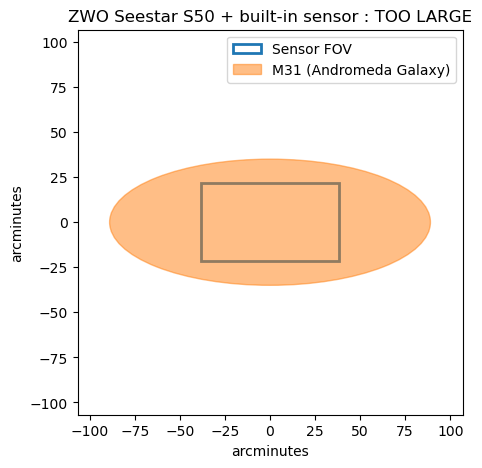

Target          : M31 (Andromeda Galaxy), 178.0′ x 70.0′
Equipment       : William Optics RedCat 51 + Canon EOS 6D
Focal length    : 250 mm (f/4.9)
Field of view   : 491.4′ x 328.4′ (8.19° x 5.47°)
Pixel sampling  : 5.40″/pixel
Frame fill      : 36% of frame (1976 px)
Verdict         : IDEAL
Advice          : Balanced framing: the target fills the sensor nicely with surrounding sky margin.


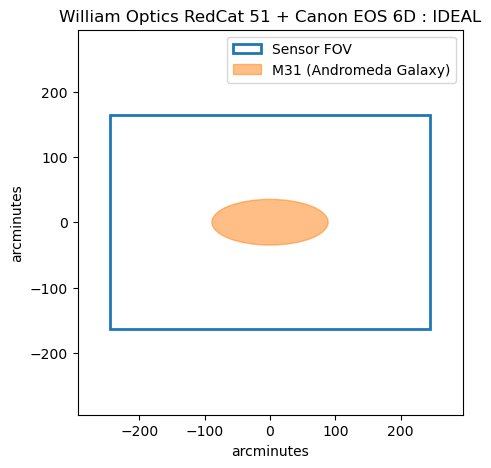

Target          : M42 (Great Orion Nebula), 85.0′ x 60.0′
Equipment       : Sky-Watcher Evostar 72ED + Canon EOS 2000D
Focal length    : 420 mm (f/5.8)
Field of view   : 182.5′ x 121.9′ (3.04° x 2.03°)
Pixel sampling  : 1.83″/pixel
Frame fill      : 49% of frame (2792 px)
Verdict         : IDEAL
Advice          : Balanced framing: the target fills the sensor nicely with surrounding sky margin.


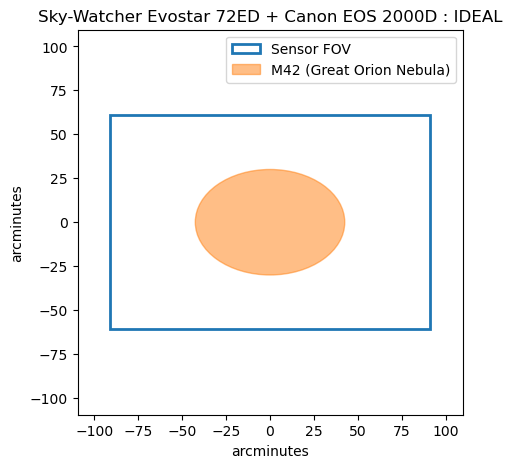

Target          : M57 (Ring Nebula), 1.4′ x 1.0′
Equipment       : Celestron NexStar 8SE + ZWO ASI533MC Pro
Focal length    : 2032 mm (f/10.0)
Field of view   : 19.1′ x 19.1′ (0.32° x 0.32°)
Pixel sampling  : 0.38″/pixel
Frame fill      : 7% of frame (220 px)
Verdict         : SMALL
Advice          : Target is small in the field but well resolved (220 px) for cropping. To enlarge it: add a 2x Barlow (4064 mm).


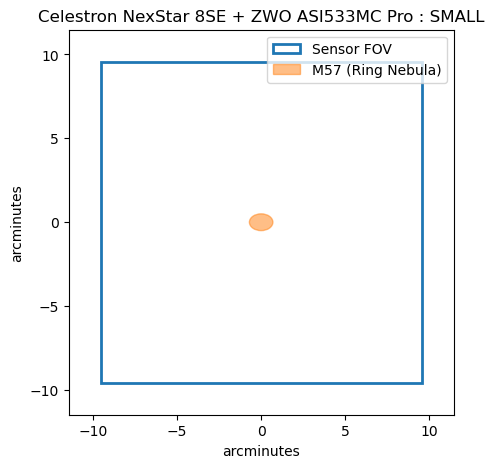

Target          : M57 (Ring Nebula), 1.4′ x 1.0′
Equipment       : William Optics RedCat 51 + ZWO ASI2600MC Pro
Focal length    : 250 mm (f/4.9)
Field of view   : 322.9′ x 215.8′ (5.38° x 3.60°)
Pixel sampling  : 3.10″/pixel
Frame fill      : 0% of frame (27 px)
Verdict         : TOO SMALL
Advice          : Target only spans 27 px: too small for this setup. Aim for a focal length of at least 1385 mm.


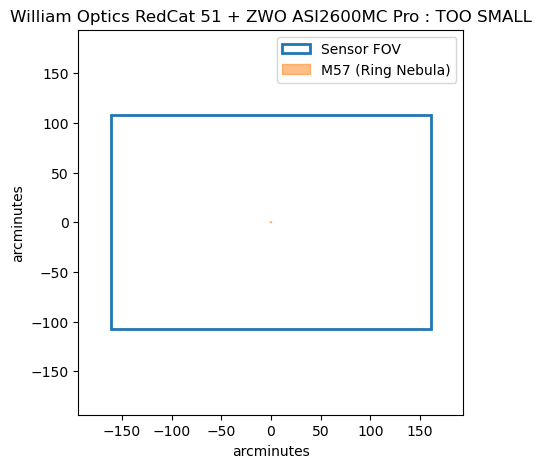

Target          : Custom Target, 30′ x 20′
Equipment       : Sky-Watcher 150PDS + Nikon D5300 + 2x Barlow
Focal length    : 1500 mm (f/10.0)
Field of view   : 53.9′ x 35.8′ (0.90° x 0.60°)
Pixel sampling  : 0.54″/pixel
Frame fill      : 56% of frame (3339 px)
Verdict         : IDEAL
Advice          : Balanced framing: the target fills the sensor nicely with surrounding sky margin.


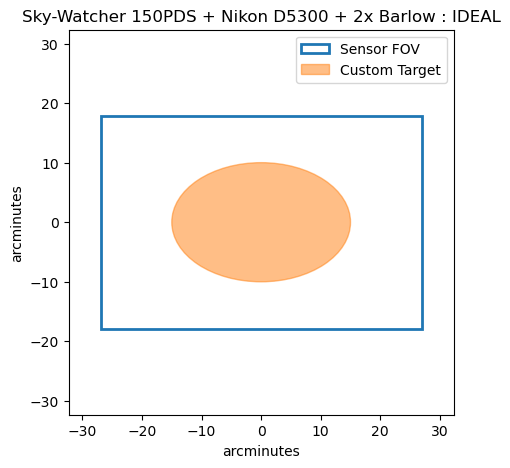

Best catalog combinations for M31:
   55%  William Optics RedCat 51 + Nikon D5300
   55%  William Optics RedCat 51 + ZWO ASI2600MC Pro
   54%  Canon EF 200mm f/2.8L + ZWO ASI294MC Pro
   58%  Askar FRA400 + ZWO ASI6200MC Pro
   58%  Celestron RASA 8 + ZWO ASI6200MC Pro


In [16]:
def analyze(target, telescope, camera=None, accessory='none', plot=True):
    if isinstance(target, str):
        key, data = find_entry(target, TARGETS)
        target_label = key + ' (' + data['name'] + ')'
    else:
        target_label, data = 'Custom Target', target

    rig = build_rig(telescope, camera, accessory)
    fov = field_of_view(rig)
    sampling = pixel_sampling(rig)
    evaluation = evaluate_framing(data, fov, sampling)
    advice_text = framing_advice(evaluation, rig, data, fov)

    rig_name = rig['name']
    f, d = rig['focal_mm'], rig['aperture_mm']
    w, h = fov['width_arcmin'], fov['height_arcmin']
    major, minor = data['size_max_arcmin'], data['size_min_arcmin']
    verdict = evaluation['verdict']
    fill_ratio, px = evaluation['fill_ratio'], evaluation['size_px']

    print(f'Target          : {target_label}, {major}′ x {minor}′')
    print(f'Equipment       : {rig_name}')
    print(f'Focal length    : {f:.0f} mm (f/{f / d:.1f})')
    print(f'Field of view   : {w:.1f}′ x {h:.1f}′ ({w / 60:.2f}° x {h / 60:.2f}°)')
    print(f'Pixel sampling  : {sampling:.2f}″/pixel')
    print(f'Frame fill      : {fill_ratio * 100:.0f}% of frame ({px:.0f} px)')
    print(f'Verdict         : {verdict}')
    print(f'Advice          : {advice_text}')
    if plot:
        plot_framing(target_label, data, fov, title=rig_name + ' : ' + verdict)
    return evaluation


# --- Examples ---
analyze('M31', 'ZWO Seestar S50')                              # too large -> mosaic
analyze('M31', 'RedCat 51', 'Canon EOS 6D')                    # wide field: ideal
analyze('M42', 'Evostar 72ED', 'Canon EOS 2000D')              # ideal
analyze('M57', 'NexStar 8SE', 'ASI533MC')                      # small but croppable
analyze('M57', 'RedCat 51', 'ASI2600MC')                       # too small
analyze({'size_max_arcmin': 30, 'size_min_arcmin': 20}, 'Sky-Watcher 150PDS', 'Nikon D5300', '2x Barlow')

print('Best catalog combinations for M31:')
for name, fill in best_combinations('M31'):
    print(f'  {fill * 100:3.0f}%  {name}')